# Нелинейность, производные и XOR

Проверим решение XOR без нелинейности и с разными активациями. Построим графики функций и производных, затем сравним обучение сетей.


## Ход работы

Сначала проверяем сеть без нелинейных преобразований на четырёх входах XOR и сравниваем её ответы с целевыми. Затем строим графики функций активации и их производных, чтобы связать форму функции с передачей градиента.

Для обучения подготавливаем одинаковые входы и сравниваем ReLU, Tanh, Sigmoid и LeakyReLU при выбранном seed. В каждом запуске записываем MSE и момент достижения порога ошибки. На общем графике сравниваем ход сходимости и проверяем итоговые ответы для всех четырёх комбинаций входов.


### Импорты, варианты активаций и демонстрационные данные

Подготавливаем четыре входа XOR и функции активации для сравнения. Важно помнить, что задача XOR нелинейна: композиция одних только линейных слоёв не может реализовать её для всех четырёх точек.

In [2]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch
from torch import nn

# Входы и правильные ответы
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])


### Пробуем сеть без нелинейности

Вручную устанавливаем веса линейных слоёв. Это учебная демонстрация конкретной конфигурации, а не обучение модели: она показывает ошибочный ответ для XOR.

In [3]:

# Нейросеть
model = nn.Sequential(
    nn.Linear(2, 2),
    nn.Linear(2, 1)
)

# Веса задаём вручную
with torch.no_grad():

    # Первый слой
    model[0].weight.copy_(
        torch.tensor([
            [1., -1.],
            [-1., 1.]
        ])
    )

    model[0].bias.zero_()

    # Выходной слой
    model[1].weight.copy_(
        torch.tensor([[1., 1.]])
    )   

    model[1].bias.zero_()


### Проверяем все четыре входа XOR

In [4]:

# Проверка
with torch.no_grad():
    predictions = model(X)

print("Входы:")
print(X)

print("\nПравильные ответы:")
print(y)

print("\nПредсказания:")
print(predictions)

print("\nMSE:", nn.MSELoss()(predictions, y).item())


import torch
import matplotlib.pyplot as plt
from torch import nn

x_values = torch.linspace(-6, 6, 500)

activations = {
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
    "ReLU": nn.ReLU(),
    "LeakyReLU": nn.LeakyReLU(0.1)
}


Входы:
tensor([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]])

Правильные ответы:
tensor([[0.],
        [1.],
        [1.],
        [0.]])

Предсказания:
tensor([[0.],
        [0.],
        [0.],
        [0.]])

MSE: 0.5


### Производные функций активации

Строим графики градиентов ReLU, Tanh, Sigmoid и LeakyReLU. Они объясняют, как `backward()` передаёт сигнал через разные области активации, включая нулевые и отрицательные входы.

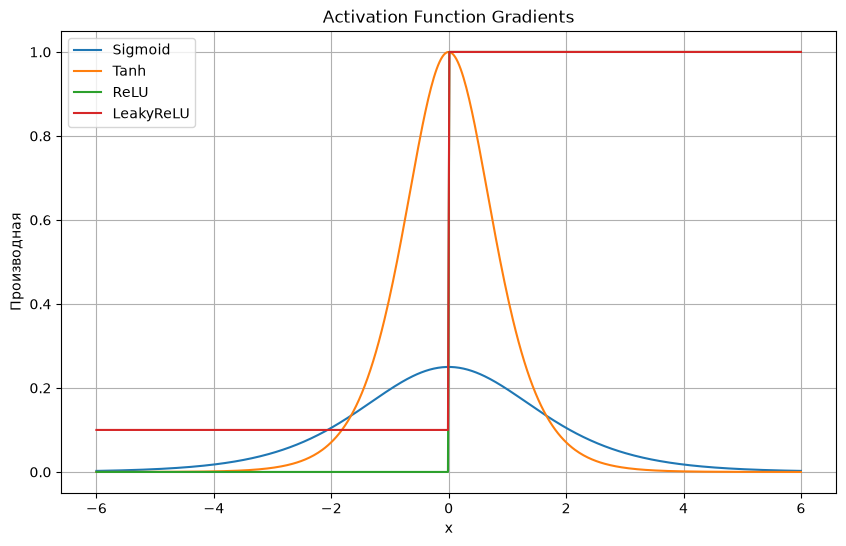

In [5]:

plt.figure(figsize=(10, 6))

for name, activation in activations.items():

    x = x_values.clone().requires_grad_(True)

    y = activation(x)

    # Вычисляем производные по всем x
    y.sum().backward()

    plt.plot(
        x.detach().numpy(),
        x.grad.detach().numpy(),
        label=name
    )

plt.xlabel("x")
plt.ylabel("Производная")
plt.title("Activation Function Gradients")
plt.grid()
plt.legend()
plt.show()


import torch
from torch import nn
import matplotlib.pyplot as plt


### Данные для обучаемого XOR

Создаём `X` формы `(4, 2)` и `y` формы `(4, 1)`. Все варианты будут учиться на одних и тех же четырёх точках; эти точки не дают оценки обобщения на новые данные.

In [6]:

X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])

activations = {
    "ReLU": nn.ReLU,
    "Tanh": nn.Tanh,
    "Sigmoid": nn.Sigmoid,
    "LeakyReLU": nn.LeakyReLU
}

target_mse = 0.001
epochs = 1000


### Обучаем четыре активации при одном seed


=== ReLU ===
Итоговая MSE: 0.0000000000
MSE < 0.001 на эпохе 72
Предсказания:
[0. 1. 1. 0.]

=== Tanh ===
Итоговая MSE: 0.0000000000
MSE < 0.001 на эпохе 88
Предсказания:
[-0.  1.  1.  0.]

=== Sigmoid ===
Итоговая MSE: 0.0000000000
MSE < 0.001 на эпохе 300
Предсказания:
[-0.  1.  1.  0.]

=== LeakyReLU ===
Итоговая MSE: 0.0000000000
MSE < 0.001 на эпохе 53
Предсказания:
[0. 1. 1. 0.]


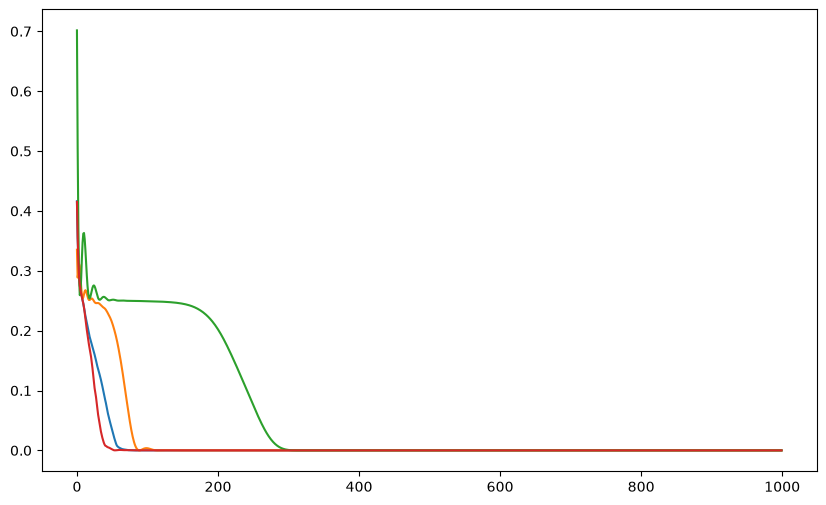

In [7]:

plt.figure(figsize=(10, 6))

# Перебираем функции активации
for name, activation in activations.items():

    torch.manual_seed(10)

    model = nn.Sequential(
        nn.Linear(2, 8),
        activation(),
        nn.Linear(8, 1)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.03
    )

    loss_fn = nn.MSELoss()

    history = []
    convergence_epoch = None

    # Обучаем текущую нейросеть
    for epoch in range(epochs):

        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_fn(predictions, y)

        loss.backward()
        optimizer.step()

        # Проверяем ошибку после обновления весов
        with torch.no_grad():
            current_loss = loss_fn(model(X), y).item()

        history.append(current_loss)

        # Запоминаем первую эпоху достижения порога
        if current_loss < target_mse and convergence_epoch is None:
            convergence_epoch = epoch + 1

    # Результаты после завершения обучения
    with torch.no_grad():
        final_predictions = model(X)
        final_mse = loss_fn(final_predictions, y).item()

    print(f"\n=== {name} ===")
    print(f"Итоговая MSE: {final_mse:.10f}")

    if convergence_epoch is not None:
        print(
            f"MSE < {target_mse} "
            f"на эпохе {convergence_epoch}"
        )
    else:
        print("Порог MSE не достигнут")

    print("Предсказания:")
    print(final_predictions.flatten().numpy().round(3))

    # Одна линия на каждую функцию активации
    plt.plot(history, label=name)


### Сравниваем кривые сходимости

Выводим кривые MSE на одном графике. После достижения ошибки почти ноль сравнение чисел порядка `10⁻¹⁶` бессмысленно: лучше смотреть на эпоху достижения выбранного порога и повторять опыт с разными seed.

C:\Users\Dad\AppData\Local\Temp\ipykernel_7892\2979445292.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


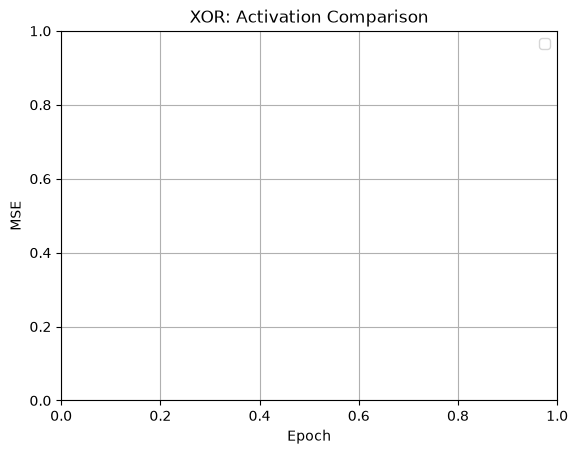

In [8]:

# Строим общий график
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("XOR: Activation Comparison")
plt.legend()
plt.grid()
plt.show()


## Выводы

Без нелинейности сеть не разделяет XOR. Активации позволяют решить задачу, но скорость достижения `MSE < 0.001` зависит от функции и начальных весов.


## Полный код


In [ ]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch
from torch import nn

# Входы и правильные ответы
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])

# Нейросеть
model = nn.Sequential(
    nn.Linear(2, 2),
    nn.Linear(2, 1)
)

# Веса задаём вручную
with torch.no_grad():

    # Первый слой
    model[0].weight.copy_(
        torch.tensor([
            [1., -1.],
            [-1., 1.]
        ])
    )

    model[0].bias.zero_()

    # Выходной слой
    model[1].weight.copy_(
        torch.tensor([[1., 1.]])
    )   

    model[1].bias.zero_()

# Проверка
with torch.no_grad():
    predictions = model(X)

print("Входы:")
print(X)

print("\nПравильные ответы:")
print(y)

print("\nПредсказания:")
print(predictions)

print("\nMSE:", nn.MSELoss()(predictions, y).item())


import torch
import matplotlib.pyplot as plt
from torch import nn

x_values = torch.linspace(-6, 6, 500)

activations = {
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
    "ReLU": nn.ReLU(),
    "LeakyReLU": nn.LeakyReLU(0.1)
}

plt.figure(figsize=(10, 6))

for name, activation in activations.items():

    x = x_values.clone().requires_grad_(True)

    y = activation(x)

    # Вычисляем производные по всем x
    y.sum().backward()

    plt.plot(
        x.detach().numpy(),
        x.grad.detach().numpy(),
        label=name
    )

plt.xlabel("x")
plt.ylabel("Производная")
plt.title("Activation Function Gradients")
plt.grid()
plt.legend()
plt.show()


import torch
from torch import nn
import matplotlib.pyplot as plt

X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])

activations = {
    "ReLU": nn.ReLU,
    "Tanh": nn.Tanh,
    "Sigmoid": nn.Sigmoid,
    "LeakyReLU": nn.LeakyReLU
}

target_mse = 0.001
epochs = 1000

plt.figure(figsize=(10, 6))

# Перебираем функции активации
for name, activation in activations.items():

    torch.manual_seed(10)

    model = nn.Sequential(
        nn.Linear(2, 8),
        activation(),
        nn.Linear(8, 1)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.03
    )

    loss_fn = nn.MSELoss()

    history = []
    convergence_epoch = None

    # Обучаем текущую нейросеть
    for epoch in range(epochs):

        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_fn(predictions, y)

        loss.backward()
        optimizer.step()

        # Проверяем ошибку после обновления весов
        with torch.no_grad():
            current_loss = loss_fn(model(X), y).item()

        history.append(current_loss)

        # Запоминаем первую эпоху достижения порога
        if current_loss < target_mse and convergence_epoch is None:
            convergence_epoch = epoch + 1

    # Результаты после завершения обучения
    with torch.no_grad():
        final_predictions = model(X)
        final_mse = loss_fn(final_predictions, y).item()

    print(f"\n=== {name} ===")
    print(f"Итоговая MSE: {final_mse:.10f}")

    if convergence_epoch is not None:
        print(
            f"MSE < {target_mse} "
            f"на эпохе {convergence_epoch}"
        )
    else:
        print("Порог MSE не достигнут")

    print("Предсказания:")
    print(final_predictions.flatten().numpy().round(3))

    # Одна линия на каждую функцию активации
    plt.plot(history, label=name)

# Строим общий график
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("XOR: Activation Comparison")
plt.legend()
plt.grid()
plt.show()
